# Beispiel 00_b - ARMA mit externen Merkmalen

**Was ändert sich, wenn wir zusätzlich zu den bisherigen Messwerten einen Plan kennen?**

Wir möchten den täglichen Energieverbrauch einer kleinen Maschine vorhersagen.
An geplanten Produktionstagen verbraucht sie mehr Energie als im Bereitschaftsbetrieb.
Der Produktionsplan steht bereits fest. Der tatsächliche zukünftige Verbrauch ist unbekannt.

Wir vergleichen zwei Modelle auf denselben Daten:

- **Ohne externes Merkmal:** nur die bisherigen Verbrauchswerte.
- **Mit externem Merkmal:** bisherige Verbrauchswerte und Produktionsplan.

Beide verwenden `ARIMA(..., order=(1, 0, 1))`. Mit `d=0` arbeiten wir ohne Differenzierung.
Die Zusatzinformation übergeben wir als **`exog`**.

## 1. Werkzeuge laden

Die Zellen von oben nach unten ausführen. Das Notebook funktioniert eigenständig.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 11})

## 2. Was ist ein externes Merkmal?

Ein externes Merkmal ist eine zusätzliche Information neben der Zielreihe.
Hier ist die Zielreihe der **Verbrauch in kWh pro Tag**. Das Merkmal heißt **Produktion**:

| Produktion | Bedeutung |
|---|---|
| 0 | Bereitschaftsbetrieb |
| 1 | Produktion geplant |

Das Modell soll aus den bisherigen Daten lernen, wie stark der Verbrauch mit diesem Plan zusammenhängt.
Wir geben ihm die Höhe des zusätzlichen Verbrauchs nicht vor.

**Wichtig:** Der zukünftige Plan ist bereits bekannt. Die zukünftigen Verbrauchswerte sind es nicht.

In [2]:
# Künstliche Daten: Der Plan gilt für alle 160 Tage bereits als festgelegt.
tage = pd.RangeIndex(1, 161, name="Tag")
produktion = pd.Series(0, index=tage, name="Produktion")
for start, ende in [(12, 25), (38, 50), (65, 78), (96, 108), (126, 137), (148, 157)]:
    produktion.loc[start:ende] = 1

# Kleine zeitlich zusammenhängende Schwankungen im Verbrauch.
rng = np.random.default_rng(42)
schocks = rng.normal(0, 0.15, len(tage))
rest = np.zeros(len(tage))
for i in range(1, len(tage)):
    rest[i] = 0.6 * rest[i-1] + schocks[i] + 0.3 * schocks[i-1]

verbrauch = pd.Series(20 + 8 * produktion.to_numpy() + rest, index=tage, name="Verbrauch")
merkmale = produktion.to_frame()

Die Zahlen 20 und 8 gehören nur zur künstlichen Datenquelle: ungefähr 20 kWh Grundverbrauch
und zusätzlich 8 kWh an Produktionstagen. Das Modell erhält diese Zahlen nicht als Vorgabe.
Es muss Grundverbrauch und Mehrverbrauch selbst schätzen.

Die kleinen Schwankungen sorgen dafür, dass nicht jeder Tag exakt gleich aussieht.

## 3. Vergangenheit und Zukunft trennen

Wir stehen am Ende von Tag 120. Die folgenden 40 Verbrauchswerte bleiben beim Lernen verborgen.
Für die Merkmale trennen wir dieselben Zeiträume ab.

In [3]:
training = verbrauch.iloc[:120]
test = verbrauch.iloc[120:]
merkmale_training = merkmale.iloc[:120]
merkmale_zukunft = merkmale.iloc[120:]

display(pd.DataFrame({
    "Verbrauch [kWh]": training,
    "Produktion": merkmale_training["Produktion"]
}).iloc[8:16].round(2))
print("Bekannte Verbrauchswerte:", len(training))
print("Vorhersagetage:", len(test))

,Verbrauch [kWh],Produktion
Tag,,
9,19.86,0
10,19.79,0
11,19.97,0
12,28.14,1
13,28.13,1
14,28.25,1
15,28.27,1
16,28.05,1


Bekannte Verbrauchswerte: 120
Vorhersagetage: 40


In der Tabelle wechselt der Plan von 0 auf 1. Gleichzeitig steigt der Verbrauch.
Die Zeilen müssen zusammenpassen: Das Merkmal für Tag 12 gehört zum Verbrauch von Tag 12.

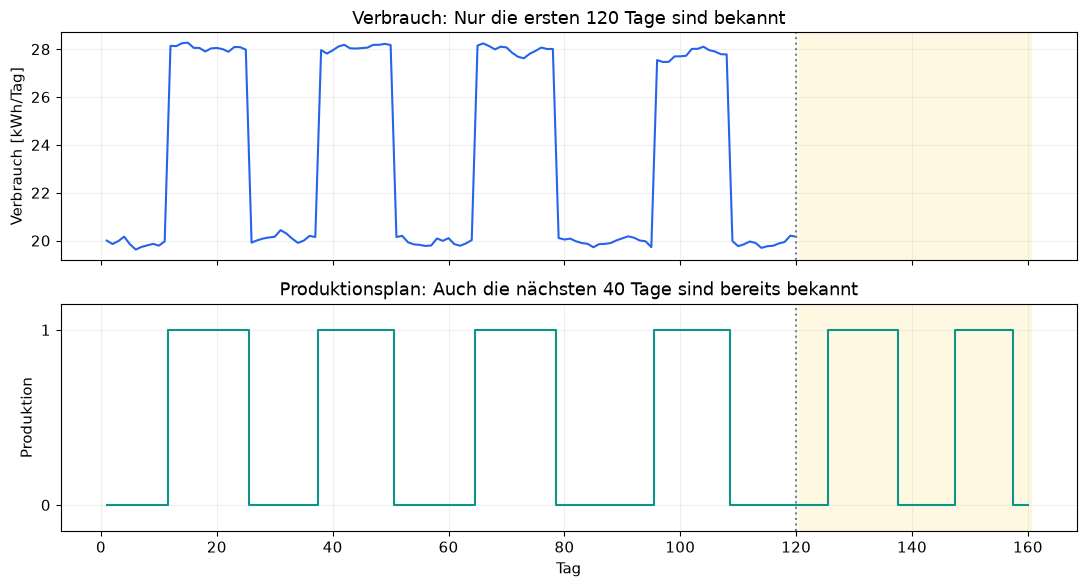

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(training, color="#2563eb")
axes[0].set(title="Verbrauch: Nur die ersten 120 Tage sind bekannt", ylabel="Verbrauch [kWh/Tag]")
axes[1].step(merkmale.index, merkmale["Produktion"], where="mid", color="#0d9488")
axes[1].set(title="Produktionsplan: Auch die nächsten 40 Tage sind bereits bekannt",
            xlabel="Tag", ylabel="Produktion", yticks=[0, 1], ylim=(-0.15, 1.15))
for ax in axes:
    ax.axvline(120, color="gray", linestyle=":")
    ax.axvspan(120.5, 160.5, color="#fef3c7", alpha=0.5)
plt.tight_layout()
plt.show()

**Was sagt mir dieser Plot?** Oben endet unser Wissen über den Verbrauch an Tag 120.
Unten reicht unser Wissen weiter: Die künftigen Produktionstage sind schon geplant.
Genau diese zusätzliche Information wollen wir nutzen.

## 4. Erst einmal ohne externes Merkmal

Das erste Modell sieht nur die vergangenen Verbrauchswerte. Es erfährt nicht,
an welchen zukünftigen Tagen wieder produziert wird.

In [5]:
modell_ohne = ARIMA(training, order=(1, 0, 1))
gelernt_ohne = modell_ohne.fit(method_kwargs={"maxiter": 1000})
vorhersage_ohne = gelernt_ohne.forecast(steps=40)

## 5. Jetzt mit Produktionsplan

Der neue Teil beim Fitten ist **`exog=merkmale_training`**.
Beim Vorhersagen kommt **`exog=merkmale_zukunft`** hinzu.

In [6]:
modell_mit = ARIMA(training, order=(1, 0, 1), exog=merkmale_training)
gelernt_mit = modell_mit.fit(method_kwargs={"maxiter": 1000})
vorhersage_mit = gelernt_mit.forecast(steps=40, exog=merkmale_zukunft)

**Was machen diese drei Zeilen?**

1. Das Modell erhält Verbrauch und Produktionsplan für die bekannten 120 Tage.
2. `.fit()` lernt den Zusammenhang und die zeitliche Struktur der verbleibenden Abweichungen.
3. `.forecast(...)` erhält den Plan für die nächsten 40 Tage und sagt deren Verbrauch vorher.

Hier spricht man häufig von **ARMAX**. Genauer schätzt diese `ARIMA`-Klasse eine Regression
auf die externen Merkmale mit ARMA-Fehlern:

**Verbrauch = gelerntes Grundniveau + gelernter Produktionseffekt + zeitlich zusammenhängender Rest.**

Die ARMA-Anteile beschreiben diesen Rest. Deshalb muss ARMA nicht die geplanten Ein- und Ausschaltzeiten erraten.

## 6. Was hat das Modell über Produktion gelernt?

Wir lesen nur die beiden leicht verständlichen Schätzwerte aus.
Die übrigen Modellparameter brauchen wir für diesen Einstieg nicht.

In [7]:
print(f"Geschätztes Grundniveau: {gelernt_mit.params['const']:.2f} kWh pro Tag")
print(f"Geschätzter Mehrverbrauch bei Produktion: {gelernt_mit.params['Produktion']:.2f} kWh pro Tag")

Geschätztes Grundniveau: 19.98 kWh pro Tag
Geschätzter Mehrverbrauch bei Produktion: 7.98 kWh pro Tag


**Wie lese ich diese Zahlen?** Bei `Produktion=0` entfällt der zusätzliche Produktionseffekt.
Bei `Produktion=1` kommt der gelernte Mehrverbrauch hinzu.
Für die nächsten Schritte kann außerdem noch die geschätzte Reststruktur nachwirken.

Die Schätzung sollte bei diesen vorbereiteten Daten ungefähr 20 und 8 ergeben.
Die Werte werden aus den Trainingsdaten gelernt und müssen nicht exakt stimmen.

## 7. Beide Prognosen im selben Bild

Jetzt decken wir die tatsächlichen 40 Testwerte zum Vergleichen auf.
Beide Prognosen wurden vorher am selben Zeitpunkt erstellt, ohne neue Verbrauchsmessungen nachzureichen.

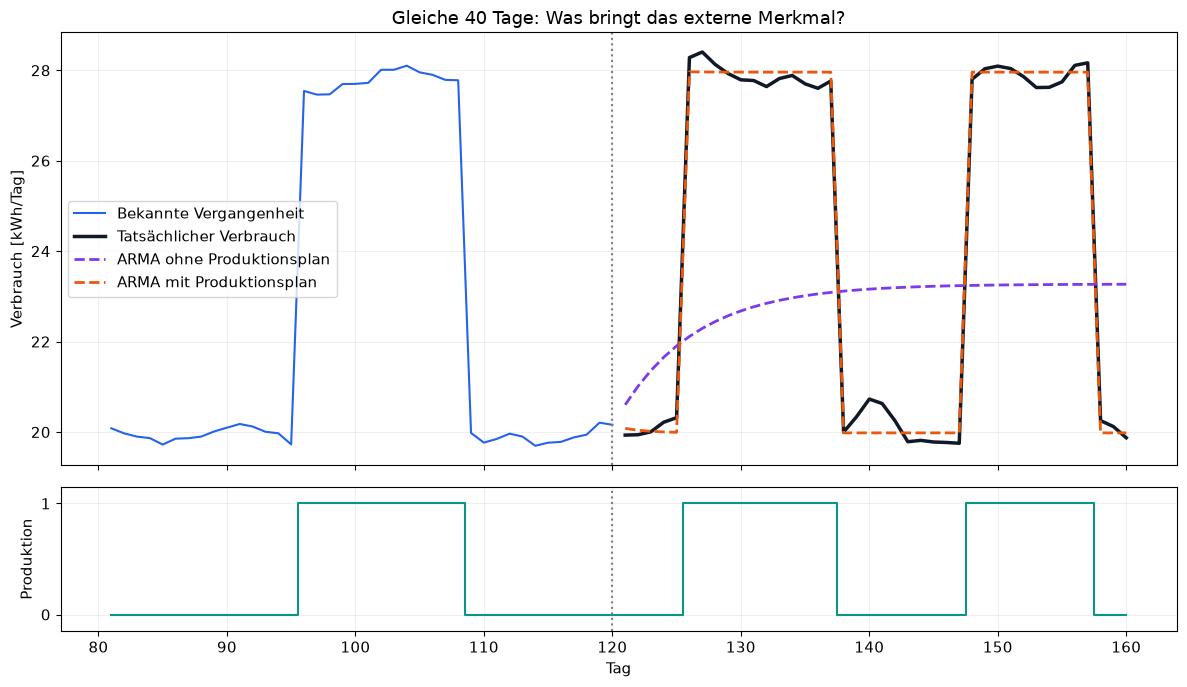

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(training.iloc[-40:], color="#2563eb", label="Bekannte Vergangenheit")
axes[0].plot(test, color="#111827", linewidth=2.5, label="Tatsächlicher Verbrauch")
axes[0].plot(vorhersage_ohne, "--", color="#7c3aed", linewidth=2, label="ARMA ohne Produktionsplan")
axes[0].plot(vorhersage_mit, "--", color="#ea580c", linewidth=2, label="ARMA mit Produktionsplan")
axes[0].set(title="Gleiche 40 Tage: Was bringt das externe Merkmal?", ylabel="Verbrauch [kWh/Tag]")
axes[0].legend()
plan_ausschnitt = merkmale.loc[81:160, "Produktion"]
axes[1].step(plan_ausschnitt.index, plan_ausschnitt, where="mid", color="#0d9488")
axes[1].set(xlabel="Tag", ylabel="Produktion", yticks=[0, 1], ylim=(-0.15, 1.15))
for ax in axes:
    ax.axvline(120, color="gray", linestyle=":")
plt.tight_layout()
plt.show()

**Was soll ich erkennen?** Die orange Prognose steigt an geplanten Produktionstagen
und fällt im Bereitschaftsbetrieb wieder ab. Der Plan gibt ihr die Zeitpunkte vor;
die Höhe des Mehrverbrauchs hat das Modell gelernt.

Die violette Prognose kennt die zukünftigen Schaltzeiten nicht. Sie bildet die kommenden
Verbrauchssprünge deshalb hier nicht passend ab.
Die kleinen zufälligen Abweichungen trifft auch das Modell mit Merkmal nicht genau.

In [9]:
mae_ohne = (test - vorhersage_ohne).abs().mean()
mae_mit = (test - vorhersage_mit).abs().mean()
display(pd.DataFrame({
    "Modell": ["ARMA ohne Produktionsplan", "ARMA mit Produktionsplan"],
    "Durchschnittlicher absoluter Fehler [kWh]": [mae_ohne, mae_mit]
}).round(2))

,Modell,Durchschnittlicher absoluter Fehler [kWh]
0,ARMA ohne Produktionsplan,3.88
1,ARMA mit Produktionsplan,0.22


Ein kleinerer Fehler ist besser. Bei diesen Daten hilft der Produktionsplan deutlich.
Das liegt an seiner echten Zusatzinformation, nicht allein daran, dass wir eine weitere Spalte eingefügt haben.

## 8. Was müssen wir für die Zukunft mitgeben?

Für 40 Vorhersageschritte benötigt dieses Modell **40 Zeilen zukünftiger Merkmale**:
dieselben Spalten in derselben Reihenfolge wie beim Fitten, passend zu den vorhergesagten Tagen.

In [10]:
print("Form der zukünftigen Merkmale:", merkmale_zukunft.shape)
display(merkmale_zukunft.head(10))

Form der zukünftigen Merkmale: (40, 1)


,Produktion
Tag,
121,0
122,0
123,0
124,0
125,0
126,1
127,1
128,1
129,1


`(40, 1)` bedeutet: 40 Tage und ein Merkmal. An Tag 126 wechselt der Plan auf Produktion.
Diese Information war bereits am Ende von Tag 120 bekannt.

| Zusatzinformation | Für die Zukunft schon verwendbar? |
|---|---|
| Festgelegter Produktionsplan | Ja, unter der Annahme, dass er eingehalten wird. |
| Wochentag oder Feiertag | Ja, aus dem Kalender bekannt. |
| Tatsächlich gemessene Temperatur von morgen | Nein, heute noch unbekannt. |
| Heute verfügbare Wettervorhersage für morgen | Als Prognose verwendbar, aber selbst unsicher. |

Die tatsächlichen zukünftigen Verbrauchswerte gehören **nicht** in `exog`.
Ändert sich der Produktionsplan, müssen auch die Merkmale für die Prognose aktualisiert werden.
Eine Vorhersage mit Merkmalen gilt immer unter den angegebenen zukünftigen Merkmalwerten.

## 9. Das bleibt hängen

**Ohne `exog`:** Das Modell kennt die bisherige Zielreihe.

**Mit `exog`:** Es bekommt zusätzliche Informationen, hier den Produktionsplan.

**Beim Fitten:** historische Merkmale passend zu den historischen Messwerten.

**Beim Vorhersagen:** zukünftige Merkmale, die zum Prognosezeitpunkt schon verfügbar sind.

Die Einstellungen waren für dieses Beispiel vorgegeben. Die Testwerte wurden erst nach dem Fitten
zum Vergleichen verwendet. Wir haben damit keine optimale Modellauswahl durchgeführt.